# Data import
What datasets are you using, later explain the variables a little bit more


In [41]:
import pandas as pd
import os
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder


In [42]:
print("Current Working Directory:", os.getcwd())


# Load the datasets
mat_data = pd.read_csv('../../student/student-mat.csv', sep=';')
por_data = pd.read_csv('../../student/student-por.csv', sep=';')

# View the first few rows
print(mat_data.head())
print(por_data.head())

Current Working Directory: c:\Users\ivoga\Documents\Git local repositories\projekt-R\testiranje\klasifikacijski_modeli\individual
  school sex  age address famsize Pstatus  ...  Walc  health absences  G1  G2  G3
0     GP   F   18       U     GT3       A  ...     1       3        6   5   6   6
1     GP   F   17       U     GT3       T  ...     1       3        4   5   5   6
2     GP   F   15       U     LE3       T  ...     3       3       10   7   8  10
3     GP   F   15       U     GT3       T  ...     1       5        2  15  14  15
4     GP   F   16       U     GT3       T  ...     2       5        4   6  10  10

[5 rows x 33 columns]
  school sex  age address famsize Pstatus  ...  Walc  health absences  G1  G2  G3
0     GP   F   18       U     GT3       A  ...     1       3        4   0  11  11
1     GP   F   17       U     GT3       T  ...     1       3        2   9  11  11
2     GP   F   15       U     LE3       T  ...     3       3        6  12  13  12
3     GP   F   15       U  

In [43]:
print(mat_data.describe())
print(por_data.describe())

              age        Medu        Fedu  ...          G1          G2          G3
count  395.000000  395.000000  395.000000  ...  395.000000  395.000000  395.000000
mean    16.696203    2.749367    2.521519  ...   10.908861   10.713924   10.415190
std      1.276043    1.094735    1.088201  ...    3.319195    3.761505    4.581443
min     15.000000    0.000000    0.000000  ...    3.000000    0.000000    0.000000
25%     16.000000    2.000000    2.000000  ...    8.000000    9.000000    8.000000
50%     17.000000    3.000000    2.000000  ...   11.000000   11.000000   11.000000
75%     18.000000    4.000000    3.000000  ...   13.000000   13.000000   14.000000
max     22.000000    4.000000    4.000000  ...   19.000000   19.000000   20.000000

[8 rows x 16 columns]
              age        Medu        Fedu  ...          G1          G2          G3
count  649.000000  649.000000  649.000000  ...  649.000000  649.000000  649.000000
mean    16.744222    2.514638    2.306626  ...   11.399076   11.

# Encoding the data
binary features are encoded using label encoding (0 and 1), 
while for categorical features one-hot encoding is used.
As for the numerical features, they are normilized using min-max scaling.

In [44]:
# encoding the binary features
binary_features = ['school', 'sex', 'address', 'famsize', 'Pstatus', 
                   'schoolsup', 'famsup', 'paid', 'activities', 
                   'nursery', 'higher', 'internet', 'romantic']

label_encoder = LabelEncoder()
for feature in binary_features:
    mat_data[feature] = label_encoder.fit_transform(mat_data[feature])
    por_data[feature] = label_encoder.fit_transform(por_data[feature])


# one-hot encoding the categorical features
categorical_features = ['Mjob', 'Fjob', 'reason', 'guardian']

mat_data = pd.get_dummies(mat_data, columns=categorical_features, drop_first=True)
por_data = pd.get_dummies(por_data, columns=categorical_features, drop_first=True)

# normalizing numeric features using min-max scaling
numeric_features = ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 
                    'failures', 'famrel', 'freetime', 'goout', 'Dalc', 
                    'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

scaler = MinMaxScaler()
mat_data[numeric_features] = scaler.fit_transform(mat_data[numeric_features])
por_data[numeric_features] = scaler.fit_transform(por_data[numeric_features])



# Binary Classification for Math data
Predict whether G3 is above or below a threshold (e.g., 0.5)


In [45]:
# Create a binary target variable
mat_data['G3_binary'] = (mat_data['G3'] > 0.5).astype(int)

# Define features and target
X_binary_mat = mat_data.drop(columns=['G3', 'G3_binary'])
y_binary_mat = mat_data['G3_binary']

In [46]:
# Split the data
X_train_binary_mat, X_test_binary_mat, y_train_binary_mat, y_test_binary_mat = train_test_split(
    X_binary_mat, y_binary_mat, test_size=0.2, random_state=42
)


In [47]:
# Train Logistic Regression Model
lr_binary_mat = LogisticRegression(max_iter=1000, random_state=42)
lr_binary_mat.fit(X_train_binary_mat, y_train_binary_mat)

LogisticRegression(max_iter=1000, random_state=42)

Binary Classification Results:
Accuracy: 0.8860759493670886
Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.87      0.88        38
           1       0.88      0.90      0.89        41

    accuracy                           0.89        79
   macro avg       0.89      0.89      0.89        79
weighted avg       0.89      0.89      0.89        79

Confusion Matrix:
[[33  5]
 [ 4 37]]


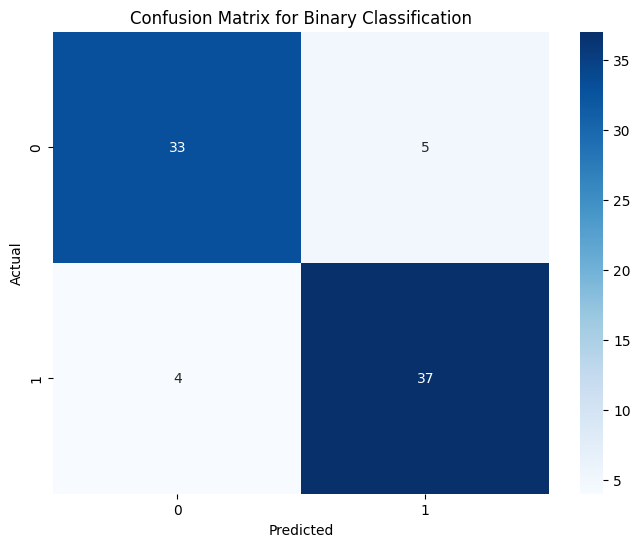

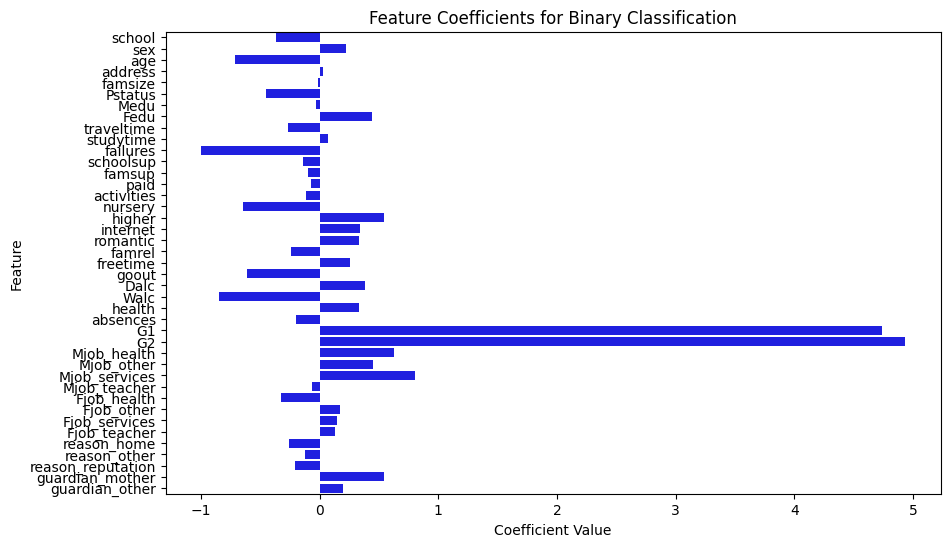

In [48]:
# Predict and evaluate
y_pred_binary_mat = lr_binary_mat.predict(X_test_binary_mat)
print("Binary Classification Results:")
print(f"Accuracy: {accuracy_score(y_test_binary_mat, y_pred_binary_mat)}")
print("Classification Report:")
print(classification_report(y_test_binary_mat, y_pred_binary_mat))
print("Confusion Matrix:")
print(confusion_matrix(y_test_binary_mat, y_pred_binary_mat))

# Visualize the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test_binary_mat, y_pred_binary_mat), annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for Binary Classification")
plt.show()

# Visualize coefficients
coefficients_binary = lr_binary_mat.coef_[0]
feature_names_binary = X_binary_mat.columns

plt.figure(figsize=(10, 6))
sns.barplot(x=coefficients_binary, y=feature_names_binary, color="b")
plt.xlabel("Coefficient Value")
plt.ylabel("Feature")
plt.title("Feature Coefficients for Binary Classification")
plt.show()

In [49]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, log_loss

# Binary Classification
print("Binary Classification Results:")
print(f"Accuracy: {accuracy_score(y_test_binary_mat, y_pred_binary_mat)}")
print(f"Precision: {precision_score(y_test_binary_mat, y_pred_binary_mat)}")
print(f"Recall: {recall_score(y_test_binary_mat, y_pred_binary_mat)}")
print(f"F1-Score: {f1_score(y_test_binary_mat, y_pred_binary_mat)}")
print(f"AUC-ROC: {roc_auc_score(y_test_binary_mat, y_pred_binary_mat)}")

# Log-Loss (use predicted probabilities)
y_pred_prob_binary = lr_binary_mat.predict_proba(X_test_binary_mat)[:, 1]
print(f"Log-Loss: {log_loss(y_test_binary_mat, y_pred_prob_binary)}")

Binary Classification Results:
Accuracy: 0.8860759493670886
Precision: 0.8809523809523809
Recall: 0.9024390243902439
F1-Score: 0.891566265060241
AUC-ROC: 0.8854300385109115
Log-Loss: 0.2808051357621935


# 5-Level Classification for Math data
Categorize G3 into 5 performance levels

In [50]:
# Create 5 levels for the target variable (G3)
mat_data['G3_5_levels'] = pd.cut(
    mat_data['G3'],
    bins=5,
    labels=[0, 1, 2, 3, 4],
    include_lowest=True
)

In [51]:
# Define features and target
X_5_levels_mat = mat_data.drop(columns=['G3', 'G3_binary', 'G3_5_levels'])
y_5_levels_mat = mat_data['G3_5_levels']

In [52]:
# Split the data
X_train_5_mat, X_test_5_mat, y_train_5_mat, y_test_5_mat = train_test_split(
    X_5_levels_mat, y_5_levels_mat, test_size=0.2, random_state=42
)

In [53]:
# Train Logistic Regression Model
lr_5_levels_mat = LogisticRegression(max_iter=1000, multi_class='multinomial', random_state=42)
lr_5_levels_mat.fit(X_train_5_mat, y_train_5_mat)

c:\Users\ivoga\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


LogisticRegression(max_iter=1000, multi_class='multinomial', random_state=42)

5-Level Classification Results:
Accuracy: 0.5189873417721519
Classification Report:
              precision    recall  f1-score   support

           0       0.50      0.20      0.29         5
           1       0.50      0.18      0.26        17
           2       0.44      0.85      0.58        26
           3       0.78      0.56      0.65        25
           4       0.33      0.17      0.22         6

    accuracy                           0.52        79
   macro avg       0.51      0.39      0.40        79
weighted avg       0.56      0.52      0.49        79

Confusion Matrix:
[[ 1  0  4  0  0]
 [ 0  3 14  0  0]
 [ 1  3 22  0  0]
 [ 0  0  9 14  2]
 [ 0  0  1  4  1]]


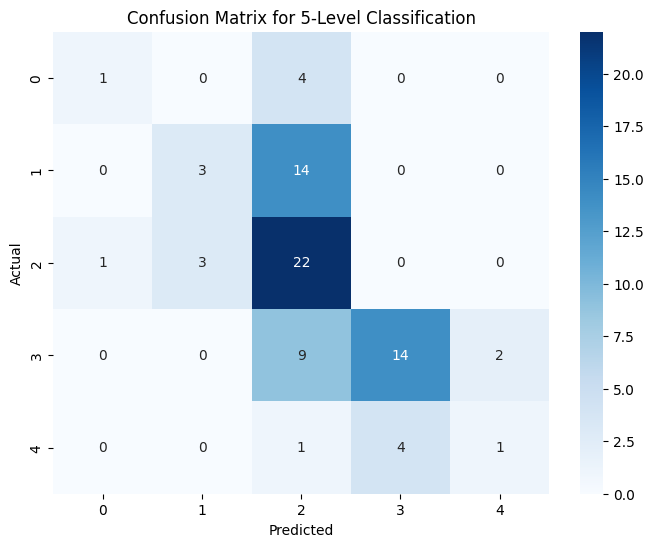

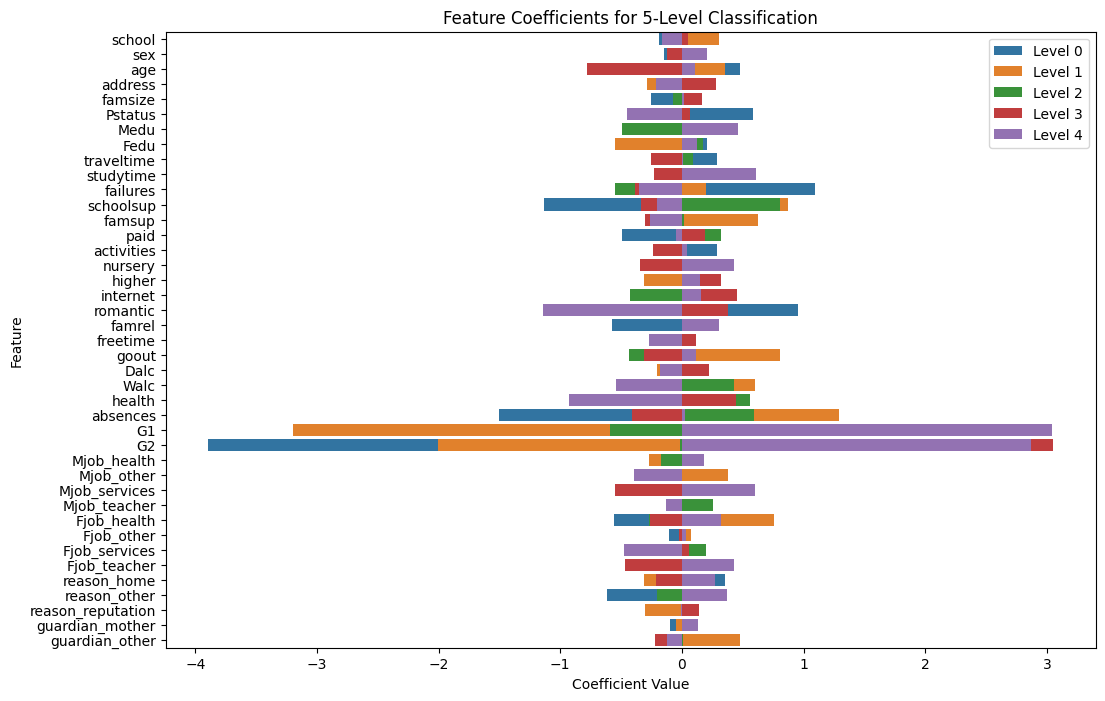

In [54]:
# Predict and evaluate
y_pred_5_mat = lr_5_levels_mat.predict(X_test_5_mat)
print("5-Level Classification Results:")
print(f"Accuracy: {accuracy_score(y_test_5_mat, y_pred_5_mat)}")
print("Classification Report:")
print(classification_report(y_test_5_mat, y_pred_5_mat))
print("Confusion Matrix:")
print(confusion_matrix(y_test_5_mat, y_pred_5_mat))

# Visualize the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test_5_mat, y_pred_5_mat), annot=True, fmt="d", cmap="Blues", 
            xticklabels=[0, 1, 2, 3, 4], yticklabels=[0, 1, 2, 3, 4])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for 5-Level Classification")
plt.show()

# Visualize coefficients
coefficients_5_levels = lr_5_levels_mat.coef_
feature_names_5_levels = X_5_levels_mat.columns

plt.figure(figsize=(12, 8))
for i in range(coefficients_5_levels.shape[0]):
    sns.barplot(x=coefficients_5_levels[i], y=feature_names_5_levels, label=f"Level {i}")
plt.xlabel("Coefficient Value")
plt.ylabel("Feature")
plt.title("Feature Coefficients for 5-Level Classification")
plt.legend()
plt.show()

# Binary Classification for Portuguese data
Predict whether G3 is above or below a threshold (e.g., 0.5)

In [55]:
# Create a binary target variable
por_data['G3_binary'] = (por_data['G3'] > 0.5).astype(int)

# Define features and target
X_binary_por = por_data.drop(columns=['G3', 'G3_binary'])
y_binary_por = por_data['G3_binary']

In [56]:
# Split the data
X_train_binary_por, X_test_binary_por, y_train_binary_por, y_test_binary_por = train_test_split(
    X_binary_por, y_binary_por, test_size=0.2, random_state=42
)

In [57]:
# Train Logistic Regression Model
lr_binary_por = LogisticRegression(max_iter=1000, random_state=42)
lr_binary_por.fit(X_train_binary_por, y_train_binary_por)

LogisticRegression(max_iter=1000, random_state=42)

Binary Classification Results:
Accuracy: 0.9076923076923077
Classification Report:
              precision    recall  f1-score   support

           0       0.64      0.47      0.54        15
           1       0.93      0.97      0.95       115

    accuracy                           0.91       130
   macro avg       0.78      0.72      0.74       130
weighted avg       0.90      0.91      0.90       130

Confusion Matrix:
[[  7   8]
 [  4 111]]


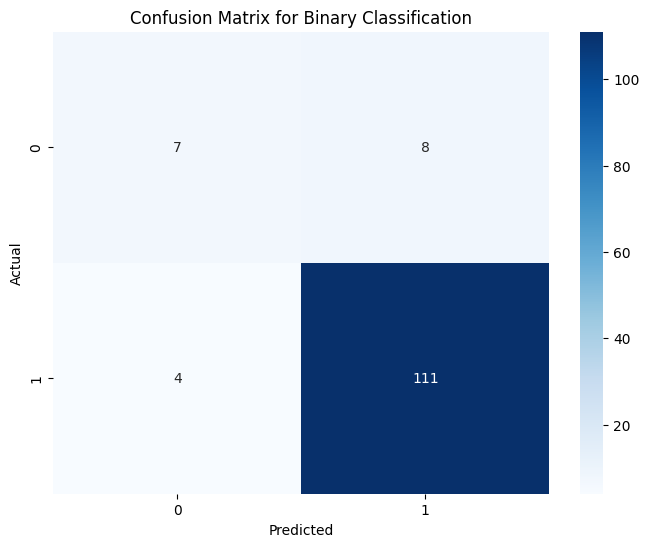

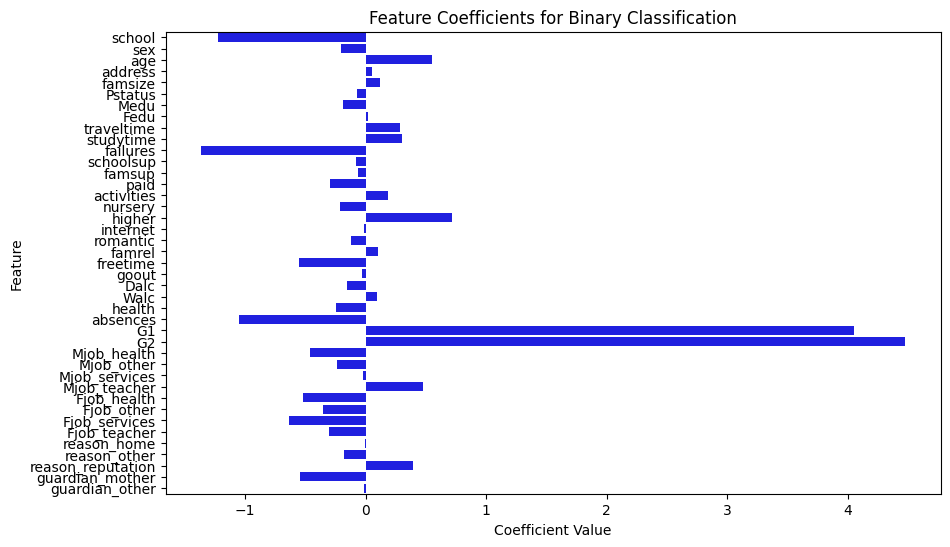

In [58]:
# Predict and evaluate
y_pred_binary_por = lr_binary_por.predict(X_test_binary_por)
print("Binary Classification Results:")
print(f"Accuracy: {accuracy_score(y_test_binary_por, y_pred_binary_por)}")
print("Classification Report:")
print(classification_report(y_test_binary_por, y_pred_binary_por))
print("Confusion Matrix:")
print(confusion_matrix(y_test_binary_por, y_pred_binary_por))

# Visualize the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test_binary_por, y_pred_binary_por), annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for Binary Classification")
plt.show()

# Visualize coefficients
coefficients_binary = lr_binary_por.coef_[0]
feature_names_binary = X_binary_por.columns

plt.figure(figsize=(10, 6))
sns.barplot(x=coefficients_binary, y=feature_names_binary, color="b")
plt.xlabel("Coefficient Value")
plt.ylabel("Feature")
plt.title("Feature Coefficients for Binary Classification")
plt.show()

In [59]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, log_loss

# Binary Classification
print("Binary Classification Results:")
print(f"Accuracy: {accuracy_score(y_test_binary_por, y_pred_binary_por)}")
print(f"Precision: {precision_score(y_test_binary_por, y_pred_binary_por)}")
print(f"Recall: {recall_score(y_test_binary_por, y_pred_binary_por)}")
print(f"F1-Score: {f1_score(y_test_binary_por, y_pred_binary_por)}")
print(f"AUC-ROC: {roc_auc_score(y_test_binary_por, y_pred_binary_por)}")

# Log-Loss (use predicted probabilities)
y_pred_prob_binary = lr_binary_por.predict_proba(X_test_binary_por)[:, 1]
print(f"Log-Loss: {log_loss(y_test_binary_por, y_pred_prob_binary)}")

Binary Classification Results:
Accuracy: 0.9076923076923077
Precision: 0.9327731092436975
Recall: 0.9652173913043478
F1-Score: 0.9487179487179487
AUC-ROC: 0.7159420289855072
Log-Loss: 0.2040725979963002


# 5-Level Classification for Portuguese data
Categorize G3 into 5 performance levels


In [60]:
# Create 5 levels for the target variable (G3)
por_data['G3_5_levels'] = pd.cut(
    por_data['G3'],
    bins=5,
    labels=[0, 1, 2, 3, 4],
    include_lowest=True
)

In [61]:
# Define features and target
X_5_levels_por = por_data.drop(columns=['G3', 'G3_binary', 'G3_5_levels'])
y_5_levels_por = por_data['G3_5_levels']

In [62]:
# Split the data
X_train_5_por, X_test_5_por, y_train_5_por, y_test_5_por = train_test_split(
    X_5_levels_por, y_5_levels_por, test_size=0.2, random_state=42
)

In [63]:
# Train Random Forest Classifier
rf_5_levels_por = LogisticRegression(random_state=42)
rf_5_levels_por.fit(X_train_5_por, y_train_5_por)

c:\Users\ivoga\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(random_state=42)

5-Level Classification Results for por_data:
Accuracy: 0.6692307692307692
Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         2
           1       0.00      0.00      0.00         1
           2       0.77      0.67      0.71        54
           3       0.59      0.82      0.69        51
           4       0.90      0.41      0.56        22

    accuracy                           0.67       130
   macro avg       0.45      0.38      0.39       130
weighted avg       0.70      0.67      0.66       130

Confusion Matrix:
[[ 0  0  2  0  0]
 [ 0  0  1  0  0]
 [ 1  1 36 16  0]
 [ 0  0  8 42  1]
 [ 0  0  0 13  9]]


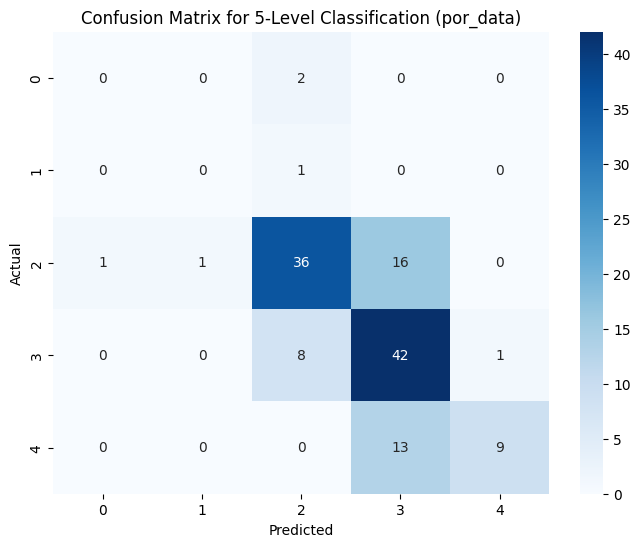

In [64]:
# Predict and evaluate
y_pred_5_por = rf_5_levels_por.predict(X_test_5_por)
print("5-Level Classification Results for por_data:")
print(f"Accuracy: {accuracy_score(y_test_5_por, y_pred_5_por)}")
print("Classification Report:")
print(classification_report(y_test_5_por, y_pred_5_por))
print("Confusion Matrix:")
print(confusion_matrix(y_test_5_por, y_pred_5_por))

# Visualize the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test_5_por, y_pred_5_por), annot=True, fmt="d", cmap="Blues", 
            xticklabels=[0, 1, 2, 3, 4], yticklabels=[0, 1, 2, 3, 4])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for 5-Level Classification (por_data)")
plt.show()

In [66]:
# Feature importance visualization for binary classification
importances_binary = lr_binary_por.feature_importances_
feature_names_binary = X_binary_por.columns

# Sorting the feature importances in descending order
sorted_indices_binary = importances_binary.argsort()[::-1]
sorted_importances_binary = importances_binary[sorted_indices_binary]
sorted_feature_names_binary = feature_names_binary[sorted_indices_binary]

plt.figure(figsize=(10, 6))
sns.barplot(x=sorted_importances_binary, y=sorted_feature_names_binary, color="b")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Feature Importance for Binary Classification")
plt.show()

# Feature importance visualization for 5-level classification
importances_5_levels = rf_5_levels_por.feature_importances_
feature_names_5_levels = X_5_levels_por.columns

# Sorting the feature importances in descending order
sorted_indices_5_levels = importances_5_levels.argsort()[::-1]
sorted_importances_5_levels = importances_5_levels[sorted_indices_5_levels]
sorted_feature_names_5_levels = feature_names_5_levels[sorted_indices_5_levels]

plt.figure(figsize=(10, 6))
sns.barplot(x=sorted_importances_5_levels, y=sorted_feature_names_5_levels, color="g")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Feature Importance for 5-Level Classification")
plt.show()

NameError: name 'rf_binary' is not defined